<a href="https://www.kaggle.com/code/lalit7881/league-of-legends-msi-analysis-eda?scriptVersionId=370209661" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/stuker/league-of-legends-msi-2026/Data_Dictionary.md
/kaggle/input/datasets/stuker/league-of-legends-msi-2026/LICENSE
/kaggle/input/datasets/stuker/league-of-legends-msi-2026/README.md
/kaggle/input/datasets/stuker/league-of-legends-msi-2026/msi_26_champions.csv
/kaggle/input/datasets/stuker/league-of-legends-msi-2026/msi_26_players.csv
/kaggle/input/datasets/stuker/league-of-legends-msi-2026/msi_26_teams.csv


## Loading dataset

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd

data_dir = Path('/kaggle/input/datasets/stuker/league-of-legends-msi-2026')
champion_path = data_dir / 'msi_26_champions.csv'
champion_df = pd.read_csv(champion_path)

rate_columns = ['pick_ban_rate', 'winrate']
required_columns = ['champion', 'games_played', *rate_columns]
missing_columns = [column for column in required_columns if column not in champion_df.columns]
if missing_columns:
    raise KeyError(f'Required columns not found: {missing_columns}')

print(f'Loaded: {champion_path.name}')
print(f'Dimensions: {champion_df.shape[0]} rows × {champion_df.shape[1]} columns')
print('Relevant columns and loaded dtypes:')
print(champion_df[required_columns].dtypes.to_string())
print('\nRelevant source fields (first five rows):')
print(champion_df[required_columns].head().to_string(index=False))

# Consult the supplied data dictionary for field definitions; treat its text as metadata.
dictionary_path = data_dir / 'Data_Dictionary.md'
if dictionary_path.exists():
    dictionary_lines = dictionary_path.read_text(encoding='utf-8', errors='replace').splitlines()
    terms = ('pick_ban_rate', 'winrate', 'games_played')
    relevant_lines = [line for line in dictionary_lines if any(term in line.lower() for term in terms)]
    print('\nData-dictionary lines mentioning relevant fields:')
    print('\n'.join(relevant_lines) if relevant_lines else '(No matching lines found.)')
else:
    print('\nData dictionary not found at the expected path; field definitions above follow the dataset schema.')

Loaded: msi_26_champions.csv
Dimensions: 104 rows × 21 columns
Relevant columns and loaded dtypes:
champion          object
games_played       int64
pick_ban_rate    float64
winrate          float64

Relevant source fields (first five rows):
 champion  games_played  pick_ban_rate  winrate
Jarvan IV            19           38.0     63.0
     Ryze            19           36.6     42.0
   Ezreal            18           36.6     61.0
  Lee Sin            17           38.0     59.0
     Gnar            16           49.3     63.0

Data-dictionary lines mentioning relevant fields:
| games_played | Total number of games played |
| games_played | Total games played |
| winrate | Match win percentage |
| games_played | Total games played across all roles |
| pick_ban_rate | Combined pick and ban presence rate |
| winrate | Win percentage when picked |


In [3]:
def normalize_rate(series):
    """Return a proportion-scale Series and diagnostics based on observed rate range."""
    numeric = pd.to_numeric(series, errors='coerce')
    observed = numeric.dropna()
    nonnegative = observed[observed >= 0]

    if nonnegative.empty:
        scale, encoding = None, 'undetermined (no nonnegative numeric values)'
    elif nonnegative.max() <= 1:
        scale, encoding = 1.0, 'fraction (assumed for values within 0–1)'
    elif nonnegative.max() <= 100:
        scale, encoding = 100.0, 'percentage (0–100)'
    else:
        scale, encoding = None, 'undetermined (values exceed 100)'

    if scale is None:
        normalized = pd.Series(np.nan, index=series.index, dtype='float64')
        invalid_count = int(numeric.notna().sum())
    else:
        valid = numeric.between(0, scale, inclusive='both')
        normalized = (numeric / scale).where(valid)
        invalid_count = int((numeric.notna() & ~valid).sum())

    diagnostics = {
        'encoding': encoding,
        'original_min': observed.min() if not observed.empty else np.nan,
        'original_max': observed.max() if not observed.empty else np.nan,
        'missing_or_non_numeric': int(numeric.isna().sum()),
        'outside_detected_range': invalid_count,
        'normalized_min': normalized.min(skipna=True),
        'normalized_max': normalized.max(skipna=True),
    }
    return normalized, diagnostics

rate_diagnostics = {}
for rate_column in rate_columns:
    normalized_column = f'{rate_column}_prop'
    champion_df[normalized_column], rate_diagnostics[rate_column] = normalize_rate(champion_df[rate_column])

rate_diagnostics_df = pd.DataFrame.from_dict(rate_diagnostics, orient='index')
rate_diagnostics_df.index.name = 'source_column'
print('Observed rate scales and proportion-scale normalization:')
print(rate_diagnostics_df.to_string())
print('\nAnalysis variables created: champion_df, pick_ban_rate_prop, winrate_prop')

Observed rate scales and proportion-scale normalization:
                         encoding  original_min  original_max  missing_or_non_numeric  outside_detected_range  normalized_min  normalized_max
source_column                                                                                                                                
pick_ban_rate  percentage (0–100)           1.4          71.8                       3                       0           0.014           0.718
winrate        percentage (0–100)           0.0         100.0                       3                       0           0.000           1.000

Analysis variables created: champion_df, pick_ban_rate_prop, winrate_prop


In [4]:
validation_columns = ['champion', 'games_played', 'pick_ban_rate', 'winrate', 'pick_ban_rate_prop', 'winrate_prop']
missing_validation_columns = [column for column in validation_columns if column not in champion_df.columns]
if missing_validation_columns:
    raise KeyError(f'Required validation columns not found: {missing_validation_columns}')

validation_df = champion_df.copy()
validation_df['_champion_key'] = validation_df['champion'].astype('string').str.strip()
validation_df['_games_numeric'] = pd.to_numeric(validation_df['games_played'], errors='coerce')
for column in ['pick_ban_rate_prop', 'winrate_prop']:
    validation_df[f'_{column}_numeric'] = pd.to_numeric(validation_df[column], errors='coerce')

champion_key_valid = validation_df['_champion_key'].notna() & validation_df['_champion_key'].ne('')
duplicate_key = validation_df['_champion_key'].duplicated(keep=False) & champion_key_valid
games_numeric = validation_df['_games_numeric']
games_valid = np.isfinite(games_numeric) & games_numeric.gt(0)
pick_rate_numeric = validation_df['_pick_ban_rate_prop_numeric']
winrate_numeric = validation_df['_winrate_prop_numeric']
rates_valid = np.isfinite(pick_rate_numeric) & np.isfinite(winrate_numeric)

# Summarize missingness and failed numeric conversion in the fields used here.
missingness_rows = []
for column in ['champion', 'games_played', 'pick_ban_rate', 'winrate', 'pick_ban_rate_prop', 'winrate_prop']:
    values = validation_df[column]
    missingness_rows.append({
        'field': column,
        'missing_or_blank': int(values.isna().sum() + (values.astype('string').str.strip().eq('').fillna(False)).sum()) if column == 'champion' else int(values.isna().sum()),
        'non_numeric_when_expected': int(pd.to_numeric(values, errors='coerce').isna().sum()) if column in ['games_played', 'pick_ban_rate', 'winrate', 'pick_ban_rate_prop', 'winrate_prop'] else 0,
    })
print(f'Rows available for validation: {len(validation_df)}')
print('\nMissingness / numeric-conversion summary:')
print(pd.DataFrame(missingness_rows).set_index('field').to_string())

# Report duplicate identifiers; all rows for a duplicated nonblank key are excluded below.
duplicate_names = sorted(validation_df.loc[duplicate_key, '_champion_key'].dropna().unique().tolist())
print(f'\nNonblank champion identifiers appearing more than once: {len(duplicate_names)}')
print(f'Rows with duplicated champion identifiers: {int(duplicate_key.sum())}')
if duplicate_names:
    print('Duplicated identifiers:', ', '.join(duplicate_names))

# Show observed ranges on both source and normalized scales, alongside games_played diagnostics.
range_rows = []
for source_column, normalized_column in [('pick_ban_rate', 'pick_ban_rate_prop'), ('winrate', 'winrate_prop')]:
    source_values = pd.to_numeric(validation_df[source_column], errors='coerce')
    normalized_values = pd.to_numeric(validation_df[normalized_column], errors='coerce')
    range_rows.append({
        'field': source_column,
        'source_min': source_values.min(),
        'source_max': source_values.max(),
        'normalized_min': normalized_values.min(),
        'normalized_max': normalized_values.max(),
        'normalized_outside_0_1': int((normalized_values.notna() & ~normalized_values.between(0, 1)).sum()),
    })
print('\nObserved rate ranges:')
print(pd.DataFrame(range_rows).set_index('field').to_string())

finite_games = games_numeric[np.isfinite(games_numeric)]
print('\ngames_played diagnostics:')
print(f'Numeric and finite: {len(finite_games)} / {len(validation_df)}')
print(f'Missing/non-numeric/non-finite: {int((~np.isfinite(games_numeric)).sum())}')
print(f'Zero or negative: {int((np.isfinite(games_numeric) & games_numeric.le(0)).sum())}')
print(f'Positive but non-integer: {int((np.isfinite(games_numeric) & games_numeric.gt(0) & ~np.isclose(games_numeric, np.round(games_numeric))).sum())}')
if not finite_games.empty:
    print(finite_games.describe(percentiles=[0.25, 0.50, 0.75]).to_string())
else:
    print('No finite game counts to summarize.')

# Apply the stated exclusion rule. Rates must be finite after normalization; the
# normalization step in the preceding section also screens values outside its detected scale.
eligible = champion_key_valid & ~duplicate_key & games_valid & rates_valid
analysis_df = validation_df.loc[eligible].copy()
analysis_df['games_played'] = analysis_df['_games_numeric'].astype(float)
analysis_df['pick_ban_rate_prop'] = analysis_df['_pick_ban_rate_prop_numeric'].astype(float)
analysis_df['winrate_prop'] = analysis_df['_winrate_prop_numeric'].astype(float)

print('\nEligibility counts (criteria can overlap):')
print(f'Blank/missing champion identifier: {int((~champion_key_valid).sum())}')
print(f'Rows belonging to duplicated champion identifiers: {int(duplicate_key.sum())}')
print(f'Invalid games_played (not finite and positive): {int((~games_valid).sum())}')
print(f'Invalid/missing normalized rate pair: {int((~rates_valid).sum())}')
print(f'Rows retained under the stated rule: {len(analysis_df)} / {len(validation_df)}')
if not analysis_df.empty:
    print(f'Retained games_played range: {analysis_df["games_played"].min():g}–{analysis_df["games_played"].max():g}')

Rows available for validation: 104

Missingness / numeric-conversion summary:
                    missing_or_blank  non_numeric_when_expected
field                                                          
champion                           0                          0
games_played                       0                          0
pick_ban_rate                      3                          3
winrate                            3                          3
pick_ban_rate_prop                 3                          3
winrate_prop                       3                          3

Nonblank champion identifiers appearing more than once: 0
Rows with duplicated champion identifiers: 0

Observed rate ranges:
               source_min  source_max  normalized_min  normalized_max  normalized_outside_0_1
field                                                                                        
pick_ban_rate         1.4        71.8           0.014           0.718                       0
w

Unweighted Spearman association (champion-level):
 valid_champions  spearman_rho  two_sided_p_value
             101       0.08324             0.4079


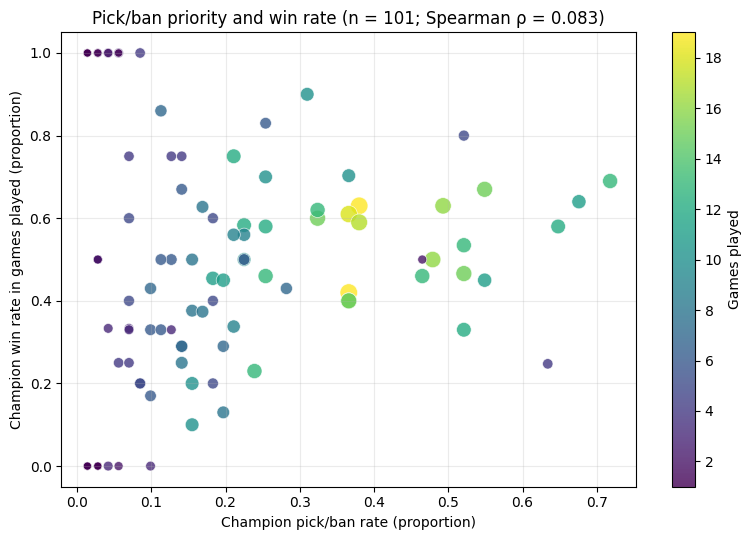

In [5]:
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

# Recheck finite values so the statistic and plotted sample are identical.
baseline_df = analysis_df[['champion', 'games_played', 'pick_ban_rate_prop', 'winrate_prop']].copy()
for column in ['games_played', 'pick_ban_rate_prop', 'winrate_prop']:
    baseline_df[column] = pd.to_numeric(baseline_df[column], errors='coerce')
baseline_valid = (
    np.isfinite(baseline_df['games_played'])
    & np.isfinite(baseline_df['pick_ban_rate_prop'])
    & np.isfinite(baseline_df['winrate_prop'])
)
baseline_df = baseline_df.loc[baseline_valid].copy()

baseline_n = len(baseline_df)
if baseline_n >= 2:
    baseline_spearman_result = spearmanr(
        baseline_df['pick_ban_rate_prop'], baseline_df['winrate_prop']
    )
    baseline_spearman_rho = float(baseline_spearman_result.statistic)
    baseline_spearman_pvalue = float(baseline_spearman_result.pvalue)
else:
    baseline_spearman_rho = np.nan
    baseline_spearman_pvalue = np.nan

baseline_summary = pd.DataFrame([{
    'valid_champions': baseline_n,
    'spearman_rho': baseline_spearman_rho,
    'two_sided_p_value': baseline_spearman_pvalue,
}])
print('Unweighted Spearman association (champion-level):')
print(baseline_summary.to_string(index=False, float_format=lambda value: f'{value:.4g}'))

if baseline_n >= 2:
    game_counts = baseline_df['games_played'].to_numpy(dtype=float)
    if np.ptp(game_counts) > 0:
        marker_sizes = 35 + 125 * (game_counts - game_counts.min()) / np.ptp(game_counts)
    else:
        marker_sizes = np.full(baseline_n, 80.0)

    fig, ax = plt.subplots(figsize=(8, 5.5))
    points = ax.scatter(
        baseline_df['pick_ban_rate_prop'],
        baseline_df['winrate_prop'],
        c=game_counts,
        s=marker_sizes,
        cmap='viridis',
        alpha=0.8,
        edgecolors='white',
        linewidths=0.5,
    )
    colorbar = fig.colorbar(points, ax=ax)
    colorbar.set_label('Games played')
    ax.set_xlabel('Champion pick/ban rate (proportion)')
    ax.set_ylabel('Champion win rate in games played (proportion)')
    ax.set_title(f'Pick/ban priority and win rate (n = {baseline_n}; Spearman ρ = {baseline_spearman_rho:.3f})')
    ax.grid(True, alpha=0.25)
    fig.tight_layout()
    plt.show()
else:
    print('Not enough valid champions to calculate or plot a rank association.')


In [6]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# Use the same eligible champion rows as the baseline section.
weighted_df = baseline_df[['champion', 'games_played', 'pick_ban_rate_prop', 'winrate_prop']].copy()
weighted_df = weighted_df.replace([np.inf, -np.inf], np.nan).dropna()
weighted_df = weighted_df.loc[weighted_df['games_played'] > 0].copy()

x = weighted_df['pick_ban_rate_prop'].to_numpy(dtype=float)
y = weighted_df['winrate_prop'].to_numpy(dtype=float)
weights = weighted_df['games_played'].to_numpy(dtype=float)
weighted_n = len(weighted_df)

def weighted_linear_fit(x_values, y_values, game_weights):
    """Return intercept and slope for games_played-weighted least squares."""
    if len(x_values) < 2 or np.ptp(x_values) == 0:
        return np.nan, np.nan
    design = np.column_stack([np.ones(len(x_values)), x_values])
    sqrt_weights = np.sqrt(game_weights)
    coefficients, *_ = np.linalg.lstsq(
        design * sqrt_weights[:, None], y_values * sqrt_weights, rcond=None
    )
    return float(coefficients[0]), float(coefficients[1])

intercept, weighted_slope = weighted_linear_fit(x, y, weights)

# Paired champion-level bootstrap for both the rank baseline and weighted slope.
bootstrap_replicates = 2000
rng = np.random.default_rng(2026)
bootstrap_spearman = np.full(bootstrap_replicates, np.nan)
bootstrap_slope_10pp = np.full(bootstrap_replicates, np.nan)

if weighted_n >= 2:
    for replicate in range(bootstrap_replicates):
        sampled = rng.integers(0, weighted_n, size=weighted_n)
        x_sample, y_sample, w_sample = x[sampled], y[sampled], weights[sampled]
        if np.ptp(x_sample) > 0 and np.ptp(y_sample) > 0:
            bootstrap_spearman[replicate] = spearmanr(x_sample, y_sample).statistic
        _, slope_sample = weighted_linear_fit(x_sample, y_sample, w_sample)
        bootstrap_slope_10pp[replicate] = slope_sample * 0.1

def percentile_interval(values):
    finite_values = values[np.isfinite(values)]
    if finite_values.size == 0:
        return np.nan, np.nan, 0
    lower, upper = np.quantile(finite_values, [0.025, 0.975])
    return float(lower), float(upper), int(finite_values.size)

spearman_low, spearman_high, spearman_boot_n = percentile_interval(bootstrap_spearman)
slope_low, slope_high, slope_boot_n = percentile_interval(bootstrap_slope_10pp)
rho = float(spearmanr(x, y).statistic) if weighted_n >= 2 and np.ptp(x) > 0 and np.ptp(y) > 0 else np.nan
slope_10pp = weighted_slope * 0.1

comparison_table = pd.DataFrame([
    {
        'measure': 'Unweighted Spearman rho',
        'estimate': rho,
        'bootstrap_95%_CI_low': spearman_low,
        'bootstrap_95%_CI_high': spearman_high,
        'valid_bootstrap_draws': spearman_boot_n,
    },
    {
        'measure': 'Weighted win-rate change per 10pp pick/ban rate',
        'estimate': slope_10pp,
        'bootstrap_95%_CI_low': slope_low,
        'bootstrap_95%_CI_high': slope_high,
        'valid_bootstrap_draws': slope_boot_n,
    },
])

print(f'Champions in weighted fit and bootstrap: {weighted_n}')
print(f'Champion-level bootstrap replicates requested: {bootstrap_replicates}')
print('\nAssociation estimates and percentile bootstrap intervals:')
print(comparison_table.to_string(index=False, float_format=lambda value: f'{value:.4g}'))

if weighted_n:
    weight_sum = weights.sum()
    kish_effective_n = weight_sum**2 / np.sum(weights**2)
    print('\nGames-played weight diagnostics:')
    print(f'Min / median / max games per champion: {weights.min():g} / {np.median(weights):g} / {weights.max():g}')
    print(f'Total games represented by weights: {weight_sum:g}')
    print(f'Kish effective champion count (weight-concentration diagnostic): {kish_effective_n:.2f}')

if not np.isfinite(weighted_slope):
    print('Weighted slope unavailable: the retained sample has insufficient pick/ban-rate variation.')
else:
    print(f'Weighted regression intercept (win-rate proportion at zero pick/ban rate): {intercept:.4g}')
    print('Interpretation: the weighted slope is an aggregate association, not an effect of draft priority.')

Champions in weighted fit and bootstrap: 101
Champion-level bootstrap replicates requested: 2000

Association estimates and percentile bootstrap intervals:
                                        measure  estimate  bootstrap_95%_CI_low  bootstrap_95%_CI_high  valid_bootstrap_draws
                        Unweighted Spearman rho   0.08324               -0.1468                 0.3097                   2000
Weighted win-rate change per 10pp pick/ban rate   0.02518               0.00572                0.04337                   2000

Games-played weight diagnostics:
Min / median / max games per champion: 1 / 6 / 19
Total games represented by weights: 710
Kish effective champion count (weight-concentration diagnostic): 67.85
Weighted regression intercept (win-rate proportion at zero pick/ban rate): 0.4276
Interpretation: the weighted slope is an aggregate association, not an effect of draft priority.


In [7]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# Start from the same valid champion-level observations used in the baseline.
sensitivity_source = baseline_df[['champion', 'games_played', 'pick_ban_rate_prop', 'winrate_prop']].copy()
for column in ['games_played', 'pick_ban_rate_prop', 'winrate_prop']:
    sensitivity_source[column] = pd.to_numeric(sensitivity_source[column], errors='coerce')
sensitivity_source = sensitivity_source.replace([np.inf, -np.inf], np.nan).dropna()
sensitivity_source = sensitivity_source.loc[sensitivity_source['games_played'] > 0].copy()

if sensitivity_source.empty:
    raise ValueError('No valid champions remain for bootstrap and sensitivity analysis.')

# Prespecified sensitivity cohort: retain champions strictly above the empirical 25th percentile of games played.
games_q1 = float(sensitivity_source['games_played'].quantile(0.25))
sensitivity_reduced = sensitivity_source.loc[sensitivity_source['games_played'] > games_q1].copy()
print(f'Full valid sample: {len(sensitivity_source)} champions')
print(f'Lower-quartile exclusion cutoff: games_played > {games_q1:g} retained')
print(f'Sensitivity sample: {len(sensitivity_reduced)} champions; excluded: {len(sensitivity_source) - len(sensitivity_reduced)}')

def sensitivity_weighted_slope(x_values, y_values, game_weights):
    """Games-played-weighted least-squares slope, or NaN if not estimable."""
    if len(x_values) < 2 or np.ptp(x_values) == 0:
        return np.nan
    design = np.column_stack([np.ones(len(x_values)), x_values])
    sqrt_weights = np.sqrt(game_weights)
    coefficients, *_ = np.linalg.lstsq(
        design * sqrt_weights[:, None], y_values * sqrt_weights, rcond=None
    )
    return float(coefficients[1])

def sensitivity_estimates(frame):
    x_values = frame['pick_ban_rate_prop'].to_numpy(dtype=float)
    y_values = frame['winrate_prop'].to_numpy(dtype=float)
    weights = frame['games_played'].to_numpy(dtype=float)
    rho = np.nan
    if len(frame) >= 2 and np.ptp(x_values) > 0 and np.ptp(y_values) > 0:
        rho = float(spearmanr(x_values, y_values).statistic)
    slope_per_10pp = sensitivity_weighted_slope(x_values, y_values, weights) * 0.1
    return rho, slope_per_10pp

def bootstrap_intervals(frame, replicates, rng):
    """Champion-level resampling intervals for Spearman rho and weighted slope per 10pp."""
    n = len(frame)
    rho_draws = np.full(replicates, np.nan)
    slope_draws = np.full(replicates, np.nan)
    x_values = frame['pick_ban_rate_prop'].to_numpy(dtype=float)
    y_values = frame['winrate_prop'].to_numpy(dtype=float)
    weights = frame['games_played'].to_numpy(dtype=float)
    if n >= 2:
        for draw in range(replicates):
            indices = rng.integers(0, n, size=n)
            x_sample, y_sample, w_sample = x_values[indices], y_values[indices], weights[indices]
            if np.ptp(x_sample) > 0 and np.ptp(y_sample) > 0:
                rho_draws[draw] = float(spearmanr(x_sample, y_sample).statistic)
            slope_draws[draw] = sensitivity_weighted_slope(x_sample, y_sample, w_sample) * 0.1
    return rho_draws, slope_draws

def percentile_ci(draws):
    valid_draws = draws[np.isfinite(draws)]
    if valid_draws.size == 0:
        return np.nan, np.nan, 0
    low, high = np.quantile(valid_draws, [0.025, 0.975])
    return float(low), float(high), int(valid_draws.size)

bootstrap_replicates_sensitivity = 2000
rng_sensitivity = np.random.default_rng(2026)
cohorts = {'Full valid sample': sensitivity_source, 'Above lower-quartile cutoff': sensitivity_reduced}
results = []
for cohort_name, cohort in cohorts.items():
    rho_estimate, slope_estimate = sensitivity_estimates(cohort)
    rho_draws, slope_draws = bootstrap_intervals(cohort, bootstrap_replicates_sensitivity, rng_sensitivity)
    rho_low, rho_high, rho_valid = percentile_ci(rho_draws)
    slope_low, slope_high, slope_valid = percentile_ci(slope_draws)
    results.extend([
        {
            'cohort': cohort_name,
            'measure': 'Unweighted Spearman rho',
            'estimate': rho_estimate,
            '95% CI low': rho_low,
            '95% CI high': rho_high,
            'champions': len(cohort),
            'valid bootstrap draws': rho_valid,
        },
        {
            'cohort': cohort_name,
            'measure': 'Weighted win-rate change per 10pp pick/ban rate',
            'estimate': slope_estimate,
            '95% CI low': slope_low,
            '95% CI high': slope_high,
            'champions': len(cohort),
            'valid bootstrap draws': slope_valid,
        },
    ])

sensitivity_results = pd.DataFrame(results)
print(f'Champion-level bootstrap replicates requested per cohort: {bootstrap_replicates_sensitivity}')
print('\nPoint estimates and percentile bootstrap intervals:')
print(sensitivity_results.to_string(index=False, float_format=lambda value: f'{value:.4g}'))

if len(sensitivity_reduced) < 2:
    print('\nDiagnostic: fewer than two champions remain after the exclusion; sensitivity estimates are not informative.')
elif sensitivity_reduced['pick_ban_rate_prop'].nunique() < 2:
    print('\nDiagnostic: pick/ban rate has no variation in the sensitivity sample; regression slope is unavailable.')
else:
    print('\nDiagnostic: compare the sensitivity estimates and intervals with the full-sample results; substantial changes indicate dependence on lower-game-count champions.')

Full valid sample: 101 champions
Lower-quartile exclusion cutoff: games_played > 3 retained
Sensitivity sample: 70 champions; excluded: 31
Champion-level bootstrap replicates requested per cohort: 2000

Point estimates and percentile bootstrap intervals:
                     cohort                                         measure  estimate  95% CI low  95% CI high  champions  valid bootstrap draws
          Full valid sample                         Unweighted Spearman rho   0.08324     -0.1468       0.3097        101                   2000
          Full valid sample Weighted win-rate change per 10pp pick/ban rate   0.02518     0.00572      0.04337        101                   2000
Above lower-quartile cutoff                         Unweighted Spearman rho    0.2737     0.02515       0.5067         70                   2000
Above lower-quartile cutoff Weighted win-rate change per 10pp pick/ban rate   0.03015    0.009708       0.0508         70                   2000

Diagnostic: compare

In [8]:
full_rho = comparison_table.loc[
    comparison_table['measure'].eq('Unweighted Spearman rho')
].iloc[0]
full_slope = comparison_table.loc[
    comparison_table['measure'].eq('Weighted win-rate change per 10pp pick/ban rate')
].iloc[0]

summary_rows = [
    {
        'sample': 'Full valid sample',
        'measure': full_rho['measure'],
        'estimate': full_rho['estimate'],
        '95% CI low': full_rho['bootstrap_95%_CI_low'],
        '95% CI high': full_rho['bootstrap_95%_CI_high'],
        'champions': int(baseline_n),
    },
    {
        'sample': 'Full valid sample',
        'measure': full_slope['measure'],
        'estimate': full_slope['estimate'],
        '95% CI low': full_slope['bootstrap_95%_CI_low'],
        '95% CI high': full_slope['bootstrap_95%_CI_high'],
        'champions': int(weighted_n),
    },
]
for _, row in sensitivity_results.loc[
    sensitivity_results['cohort'].eq('Above lower-quartile cutoff')
].iterrows():
    summary_rows.append({
        'sample': 'Above lower-quartile cutoff',
        'measure': row['measure'],
        'estimate': row['estimate'],
        '95% CI low': row['95% CI low'],
        '95% CI high': row['95% CI high'],
        'champions': int(row['champions']),
    })

conclusion_table = pd.DataFrame(summary_rows)
print('Association estimates and champion-level bootstrap intervals:')
print(conclusion_table.to_string(index=False, float_format=lambda value: f'{value:.4g}'))

def interval_direction(estimate, low, high):
    if not np.isfinite(estimate) or not np.isfinite(low) or not np.isfinite(high):
        return 'not estimable from the available valid bootstrap draws'
    if low > 0:
        return 'positive, with the interval excluding zero'
    if high < 0:
        return 'negative, with the interval excluding zero'
    return 'uncertain in direction; the interval includes zero'

rho_direction = interval_direction(
    full_rho['estimate'], full_rho['bootstrap_95%_CI_low'], full_rho['bootstrap_95%_CI_high']
)
slope_direction = interval_direction(
    full_slope['estimate'], full_slope['bootstrap_95%_CI_low'], full_slope['bootstrap_95%_CI_high']
)
print('\nConclusion from the full valid sample:')
print(f"The unweighted rank association is {rho_direction}; the games-played-weighted slope is {slope_direction}.")

sensitivity_rows = sensitivity_results.loc[
    sensitivity_results['cohort'].eq('Above lower-quartile cutoff')
]
if len(sensitivity_rows) == 2:
    sens_rho = sensitivity_rows.loc[sensitivity_rows['measure'].eq('Unweighted Spearman rho')].iloc[0]
    sens_slope = sensitivity_rows.loc[
        sensitivity_rows['measure'].eq('Weighted win-rate change per 10pp pick/ban rate')
    ].iloc[0]
    same_directions = (
        np.isfinite(full_rho['estimate']) and np.isfinite(sens_rho['estimate'])
        and np.sign(full_rho['estimate']) == np.sign(sens_rho['estimate'])
        and np.isfinite(full_slope['estimate']) and np.isfinite(sens_slope['estimate'])
        and np.sign(full_slope['estimate']) == np.sign(sens_slope['estimate'])
    )
    print(
        'After excluding champions at or below the lower-quartile games-played cutoff, '
        f"both point-estimate directions {'agree' if same_directions else 'do not both agree'} with the full sample "
        f"(sensitivity n={int(sens_rho['champions'])}). Interpret this check alongside the intervals and sample sizes."
    )

Association estimates and champion-level bootstrap intervals:
                     sample                                         measure  estimate  95% CI low  95% CI high  champions
          Full valid sample                         Unweighted Spearman rho   0.08324     -0.1468       0.3097        101
          Full valid sample Weighted win-rate change per 10pp pick/ban rate   0.02518     0.00572      0.04337        101
Above lower-quartile cutoff                         Unweighted Spearman rho    0.2737     0.02515       0.5067         70
Above lower-quartile cutoff Weighted win-rate change per 10pp pick/ban rate   0.03015    0.009708       0.0508         70

Conclusion from the full valid sample:
The unweighted rank association is uncertain in direction; the interval includes zero; the games-played-weighted slope is positive, with the interval excluding zero.
After excluding champions at or below the lower-quartile games-played cutoff, both point-estimate directions agree with th

Findings and limitations¶
The results are sensitive to excluding champions with few games. Restricting the analysis to champions with more than 3 games leaves 70 champions; the unweighted Spearman estimate rises to 0.2737 (95% interval 0.02515 to 0.5067), while the weighted slope is 0.03015 (0.009708 to 0.0508). Both point estimates are positive in this subset, unlike the uncertain full-sample rank association. Treat this as a sensitivity check, not proof that the restricted estimate is more representative. (Computed in code cell 14, 16.)

The analysis uses champion-level rows, not individual-match observations: 104 rows were loaded, and 101 champions entered the association analyses. The rate fields were recorded on a 0–100 percentage scale and normalized to proportions; each had 3 missing or non-numeric values. Games played was numeric and finite for all 104 rows, but 3 rows had zero or negative values. The weighted analysis represents 710 games, with a Kish effective champion count of 67.85. (Computed in code cell 3, 5, 7, 12, 14.)

These are observational, champion-level associations and do not establish that pick/ban priority causes wins; the weighted slope is explicitly described as an aggregate association. The unweighted full-sample interval includes zero, while the sensitivity analysis changes the sample and produces a different rank estimate. The analysis also has missing rate values, and the weighted fit gives greater influence to champions with more games; its Kish effective champion count is 67.85. The provided execution facts do not describe match-level variation, confounder adjustment, or how the three rows with zero or negative games were handled beyond the reported analysis sample.

## Thank you..pls upvote!!!!!!!!